 TASK 3 – Sales Prediction Model

**Dataset:** `superstore_cleaned(4).csv`  
**Target column:** `sales`

This notebook performs data exploration, feature engineering, an 80/20 chronological split, Linear Regression and Random Forest training, model evaluation, feature importance, actual-vs-predicted visualization, and hyperparameter tuning.


In [ ]:
# 1, Import Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score



In [ ]:
df = pd.read_csv("/content/superstore_cleaned.csv")
print(df.head())

   row_id        order_id  order_date   ship_date customer_id  customer_name  \
0       1  CA-2023-809570  2023-04-25  2023-04-26       고객704      Amit Shah   
1       2  CA-2023-717889  2023-01-28  2023-02-02       고객928  Olivia Martin   
2       3  CA-2025-733052  2025-02-20  2025-02-23       고객926   Alex Johnson   
3       4  CA-2024-910620  2024-09-25  2024-10-02       고객181  Olivia Martin   
4       5  CA-2024-660086  2024-01-15  2024-01-18       고객267    Emily Brown   

         country          city         state  postal_code  ...  \
0  United States       Seattle    Washington          0.0  ...   
1  United States       Houston         Texas      60601.0  ...   
2  United States   Los Angeles    California      92101.0  ...   
3  United States  Philadelphia  Pennsylvania      90001.0  ...   
4  United States     houston           Texas      85001.0  ...   

  segment_Consumer segment_Corporate segment_Home Office  category_Furniture  \
0                1                 0      

In [ ]:
df.shape

(303, 35)

In [ ]:
df.isnull().sum()

,0
row_id,0
order_id,0
order_date,10
ship_date,0
customer_id,0
customer_name,0
country,0
city,0
state,0
postal_code,0


Upload the CSV file, then load it with Pandas. `head()` shows the first five rows, `shape` shows the number of rows and columns, and `isnull().sum()` counts missing values.


In [ ]:
# 2. Create  New Features

# Convert order date into date format
df['order_date'] = pd.to_datetime(df['order_date'], errors='coerce')
df['sales'] = pd.to_numeric(df['sales'], errors='coerce')

# Remove rows without date or sales
df = df.dropna(subset=['order_date', 'sales'])

# Arrange orders by date
df = df.sort_values('order_date').reset_index(drop=True)

# Create date features
df['year'] = df['order_date'].dt.year
df['month'] = df['order_date'].dt.month
df['day'] = df['order_date'].dt.day

# Previous order sales and average of previous 3 orders
df['previous_sales'] = df['sales'].shift(1)
df['average_sales'] = df['sales'].shift(1).rolling(3).mean()

# Remove rows where previous sales are not available
df = df.dropna(subset=['previous_sales', 'average_sales'])

print(df.head())


   row_id        order_id order_date   ship_date customer_id  customer_name  \
3     197  CA-2023-855777 2023-01-12  2023-01-14       고객270   Sarah Wilson   
4     105  CA-2023-744674 2023-01-17  2023-01-23       고객346     Neha Joshi   
5       2  CA-2023-717889 2023-01-28  2023-02-02       고객928  Olivia Martin   
6     180  CA-2023-276379 2023-02-01  2023-02-08       고객679     Ananya Rao   
7      78  CA-2023-847006 2023-02-01  2023-02-02       고객175   Maria Garcia   

         country       city       state  postal_code  ... category_Technology  \
3  United States  San Diego  California      98101.0  ...                   1   
4  United States     Dallas       Texas      60601.0  ...                   1   
5  United States    Houston       Texas      60601.0  ...                   1   
6  United States    Houston       Texas      75201.0  ...                   1   
7  United States  San Diego  California      95101.0  ...                   1   

  region_Central region_East  region_S

We create year, month and day from the order date. `previous_sales` stores the previous order's sales. `average_sales` calculates the average of the previous three orders. `shift(1)` avoids using the current order's sales as an input for itself.


In [ ]:
# Select Features and Prepare data

# Features
X = df[['quantity', 'discount', 'year', 'month', 'day',
        'previous_sales', 'average_sales',
        'city', 'state', 'sub_category']]

# Target
y = df['sales']

# Convert text columns
X = pd.get_dummies(X)

# Fill missing values
X = X.fillna(X.median(numeric_only=True))

# Split data
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))

Training rows: 224
Testing rows: 56


X → Input columns used to predict sales.

y → Sales column (output/target).

pd.get_dummies() → Converts
text values like Ahmedabad, Mumbai, Furniture into numbers.

fillna() → Fills missing values.

80% Training Data → Used to train the model.

20% Testing Data → Used to test model accuracy.

In [ ]:
# Train Linear Regression Model

model1 = LinearRegression()
model1.fit(X_train, y_train)

pred1 = model1.predict(X_test)

print("First 10 predictions:", pred1[:10])

First 10 predictions: [ 500.16954326  795.33466272  855.48093428 1144.77839778 1055.74941663
  704.99762239  618.89690034  659.84430473 1113.01056131  960.38343803]


Linear Regression is the first, basic model. It learns a relationship between the input columns and sales.


In [ ]:
# Train random Forest MOdel
model2 = RandomForestRegressor(random_state=42)
model2.fit(X_train, y_train)

pred2 = model2.predict(X_test)

print("First 10 predictions:", pred2[:10])

First 10 predictions: [ 660.4905  872.1498  832.1342 1064.5083 1172.811   920.7346  954.1055
  676.529  1008.6316  712.1156]


Random Forest uses many decision trees to predict sales. We compare it with Linear Regression.

In [ ]:
# Model Evaluation

print("Linear Regression")
print("MAE:", mean_absolute_error(y_test, pred1))
print("R² Score:", r2_score(y_test, pred1))

print("\nRandom Forest")
print("MAE:", mean_absolute_error(y_test, pred2))
print("R² Score:", r2_score(y_test, pred2))

Linear Regression
MAE: 490.51496264287806
R² Score: -0.40959482237666256

Random Forest
MAE: 470.26043035714287
R² Score: -0.18208947495334882


In [ ]:
# Compare Model Performance

results = pd.DataFrame({
    "Model": ["Linear Regression", "Random Forest"],
    "MAE": [
        mean_absolute_error(y_test, pred1),
        mean_absolute_error(y_test, pred2)
    ],
    "R2 Score": [
        r2_score(y_test, pred1),
        r2_score(y_test, pred2)
    ]
})

print(results.round(2))

               Model     MAE  R2 Score
0  Linear Regression  490.51     -0.41
1      Random Forest  470.26     -0.18


R2 score and MAE measure prediction errors; lower values are better. R² measures how well the model explains changes in sales; a value closer to 1 is generally better. A negative R² means the model performed poorly on the test data.

In [ ]:
# Top 10 Important Features (Random Forest)

importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": model2.feature_importances_
})

importance = importance.sort_values(
    by="Importance",
    ascending=False
).head(10)

print(importance)

                     Feature  Importance
5              average_sales    0.191458
4             previous_sales    0.141636
3                        day    0.117998
2                      month    0.080171
0                   quantity    0.059631
51       sub_category_Chairs    0.036134
1                       year    0.024425
44               state_Texas    0.022481
53  sub_category_Furnishings    0.016709
45          state_Washington    0.016178


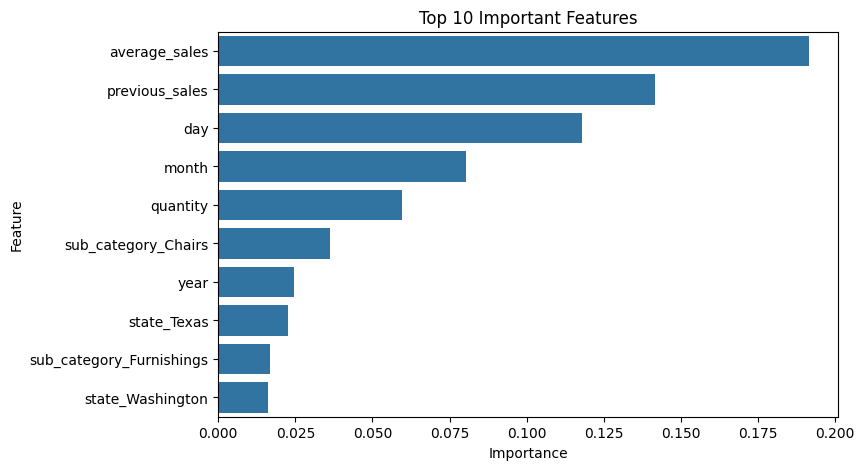

In [ ]:
# Feature Importance Chart

plt.figure(figsize=(8,5))
sns.barplot(
x="Importance",
y="Feature",
data=importance
)
plt.title("Top 10 Important Features")
plt.show()




 This chart shows the features that Random Forest used most when making predictions. .

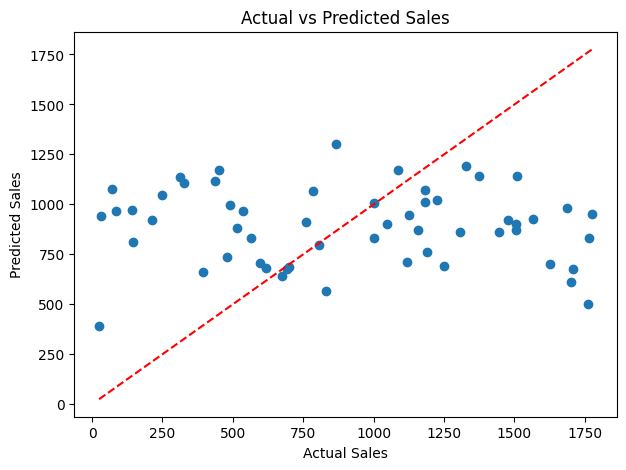

In [ ]:
# Actual vs Predicted Sales
plt.figure(figsize=(7, 5))
plt.scatter(y_test, pred2)

# Red line shows where perfect predictions would fall
low = min(y_test.min(), pred2.min())
high = max(y_test.max(), pred2.max())
plt.plot([low, high], [low, high], 'r--')

plt.xlabel('Actual Sales')
plt.ylabel('Predicted Sales')
plt.title('Actual vs Predicted Sales')

plt.show()

Points close to the red line indicate better predictions. Points far from the line indicate larger errors.


In [ ]:
# Tune Random Forest

# Parameters to try
params = {
    'n_estimators': [50, 100],
    'max_depth': [5, 10]
}

# Grid Search
grid = GridSearchCV(model2, params, cv=3)

# Train
grid.fit(X_train, y_train)

# Best model
best_model = grid.best_estimator_

# Prediction
predictions = best_model.predict(X_test)

# Best parameters
print("Best Parameters:", grid.best_params_)


Best Parameters: {'max_depth': 5, 'n_estimators': 50}


"GridSearchCV was used to tune the Random Forest model by testing different numbers of trees and tree depths. The best parameter combination was selected automatically and used for prediction."


In [ ]:
print("Final RMSE:", np.sqrt(mean_squared_error(y_test, predictions)))
print("Final MAE:", mean_absolute_error(y_test, predictions))
print("Final R2 Score:", r2_score(y_test, predictions))

Final RMSE: 554.0730702589312
Final MAE: 463.67914148120275
Final R2 Score: -0.10952807968269673


These are the final scores for the tuned Random Forest model. Compare them with the earlier Random Forest scores to see whether tuning helped.

## Final project conclusion

In this project, I used the Superstore dataset to predict sales using machine learning. I created date and previous-sales features, split the data into 80% training and 20% testing, and trained Linear Regression and Random Forest models. I compared the models using RMSE, MAE and R-squared. I also created feature-importance and actual-versus-predicted charts and tuned Random Forest using GridSearchCV.

**Business use:** The model can help a business study sales patterns and support planning. The dataset is small, so the predictions may not be reliable enough for real business decisions. More historical data and additional useful features may improve performance.

